In [66]:
import numpy as np
import matplotlib.pyplot as plt

In [67]:
data1 = np.loadtxt("data1.csv", delimiter=',', dtype=float, usecols=range(30))
data2 = np.loadtxt("data2.csv", delimiter=',', dtype=float, usecols=range(36))
step = data1[:,0]
T= data1[:,1]

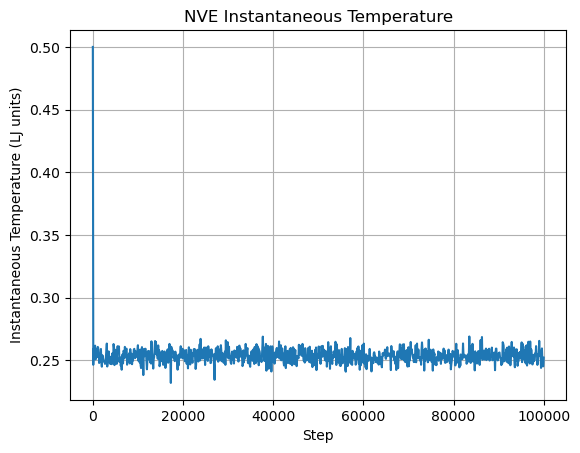

In [68]:
plt.figure()
plt.plot(step, T)
plt.xlabel("Step")
plt.ylabel("Instantaneous Temperature (LJ units)")
plt.title("NVE Instantaneous Temperature")
plt.grid()
plt.savefig("b1.png")
plt.show()

In [69]:
mask = step >= 1000
T_eq = T[mask]

mean_T = np.mean(T_eq)
sigma_T = np.std(T_eq, ddof=1)
relative_width = sigma_T / mean_T

print("Mean T =", mean_T)
print("Sigma T =", sigma_T)
print("Relative width =", relative_width)
print("Relative width (%) =", relative_width * 100)

Mean T = 0.25350347112008076
Sigma T = 0.005079835303664104
Relative width = 0.020038523658943756
Relative width (%) = 2.0038523658943754


In [70]:
#thermostat
bT = data1[:,7]
lT = data1[:,13]
nT = data1[:,19]

In [71]:
bT_eq = bT[mask]
lT_eq = lT[mask]
nT_eq = nT[mask]

mean_bT = np.mean(bT_eq)
sigma_bT = np.std(bT_eq, ddof=1)
relative_width_b = sigma_bT / mean_bT

mean_lT = np.mean(lT_eq)
sigma_lT = np.std(lT_eq, ddof=1)
relative_width_l = sigma_lT / mean_lT

mean_nT = np.mean(nT_eq)
sigma_nT = np.std(nT_eq, ddof=1)
relative_width_n = sigma_nT / mean_nT

print("Berendsen:")
print("Mean T =", mean_bT)
print("Sigma T =", sigma_bT)
print("Relative width =", relative_width_b)
print("Relative width (%) =", relative_width_b * 100)

print("Langevin:")
print("Mean T =", mean_lT)
print("Sigma T =", sigma_lT)
print("Relative width =", relative_width_l)
print("Relative width (%) =", relative_width_l * 100)

print("Nose-Hoover:")
print("Mean T =", mean_nT)
print("Sigma T =", sigma_nT)
print("Relative width =", relative_width_n)
print("Relative width (%) =", relative_width_n * 100)

Berendsen:
Mean T = 0.24990106635721496
Sigma T = 0.004493739833134597
Relative width = 0.01798207546145934
Relative width (%) = 1.798207546145934
Langevin:
Mean T = 0.25039129600403637
Sigma T = 0.0067644870484127925
Relative width = 0.027015663708628863
Relative width (%) = 2.7015663708628863
Nose-Hoover:
Mean T = 0.25007316677093844
Sigma T = 0.006671831873894729
Relative width = 0.02667951927847573
Relative width (%) = 2.667951927847573


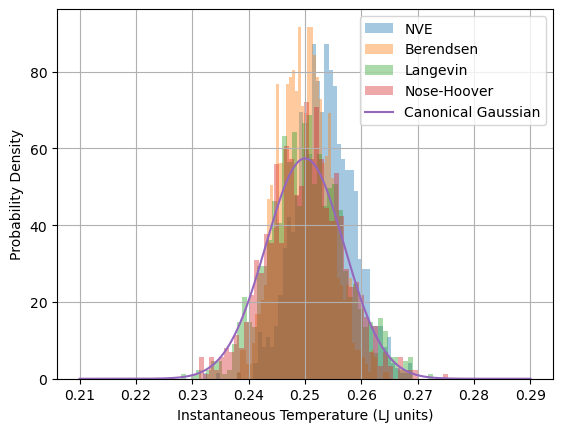

In [72]:
mu = 0.25
sigma = 0.25*np.sqrt(2/2589)
x = np.linspace(0.21, 0.29, 500)
gaussian = (1/(sigma*np.sqrt(2*np.pi)) * np.exp(-(x-mu)**2/(2*sigma**2)))

plt.figure()
plt.hist(T_eq, bins=50, density=True, alpha=0.4, label="NVE")
plt.hist(bT_eq, bins=50, density=True, alpha=0.4, label="Berendsen")
plt.hist(lT_eq, bins=50, density=True, alpha=0.4, label="Langevin")
plt.hist(nT_eq, bins=50, density=True, alpha=0.4, label="Nose-Hoover")
plt.plot(x, gaussian, label="Canonical Gaussian")
plt.xlabel("Instantaneous Temperature (LJ units)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid()
plt.savefig("c1.png")
plt.show()

In [73]:
bmT = data1[:,25]
bmT_eq = bmT[mask]
mean_bmT = np.mean(bmT_eq)
sigma_bmT = np.std(bmT_eq, ddof=1)
relative_width_bm = sigma_bmT / mean_bmT
print("Berendsen modified:")
print("Mean T =", mean_bmT)
print("Sigma T =", sigma_bmT)
print("Relative width =", relative_width_bm)
print("Relative width (%) =", relative_width_bm * 100)

Berendsen modified:
Mean T = 0.24985858630676083
Sigma T = 0.003331148973580762
Relative width = 0.013332137281409992
Relative width (%) = 1.3332137281409993


In [74]:
step = data2[:,0]

vcmxb = data2[:,6]
vcmyb = data2[:,7]
vcmzb = data2[:,8]
vcmb = np.sqrt(vcmxb**2 + vcmyb**2 + vcmzb**2)

vcmxl = data2[:,15]
vcmyl = data2[:,16]
vcmzl = data2[:,17]
vcml = np.sqrt(vcmxl**2 + vcmyl**2 + vcmzl**2)

vcmxn = data2[:,24]
vcmyn = data2[:,25]
vcmzn = data2[:,26]
vcmn = np.sqrt(vcmxn**2 + vcmyn**2 + vcmzn**2)

vcmxln = data2[:,33]
vcmyln = data2[:,34]
vcmzln = data2[:,35]
vcmln = np.sqrt(vcmxln**2 + vcmyln**2 + vcmzln**2)

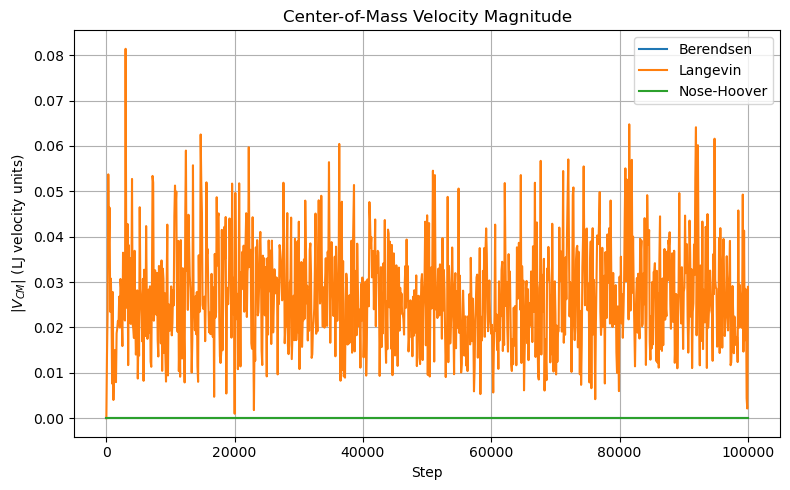

In [77]:
plt.figure(figsize=(8, 5))
plt.plot(step, vcmb, label="Berendsen")
plt.plot(step, vcml, label="Langevin")
plt.plot(step, vcmn, label="Nose-Hoover")
plt.xlabel("Step")
plt.ylabel(r"$|V_{CM}|$ (LJ velocity units)")
plt.title("Center-of-Mass Velocity Magnitude")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("d1.png")
plt.show()

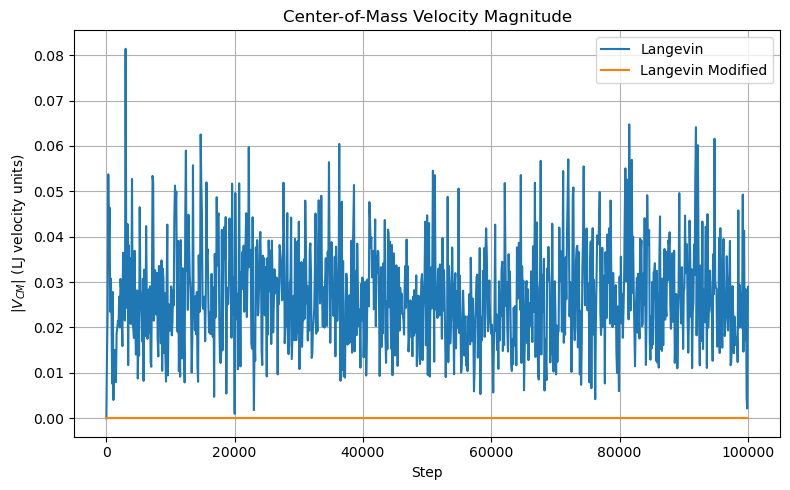

In [78]:
plt.figure(figsize=(8, 5))
plt.plot(step, vcml, label="Langevin")
plt.plot(step, vcmln, label="Langevin Modified")
plt.xlabel("Step")
plt.ylabel(r"$|V_{CM}|$ (LJ velocity units)")
plt.title("Center-of-Mass Velocity Magnitude")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("d12.png")
plt.show()

Block size = 1 Number of blocks = 991 Error = 0.00021193800928639539
Block size = 2 Number of blocks = 495 Error = 0.00024223130982827144
Block size = 4 Number of blocks = 247 Error = 0.00023731317564079955
Block size = 8 Number of blocks = 123 Error = 0.00025214780646943776
Block size = 16 Number of blocks = 61 Error = 0.0002837484616583356
Block size = 32 Number of blocks = 30 Error = 0.0003204404037936673
Block size = 64 Number of blocks = 15 Error = 0.00039827700059518297
Block size = 128 Number of blocks = 7 Error = 0.00037143911108524614


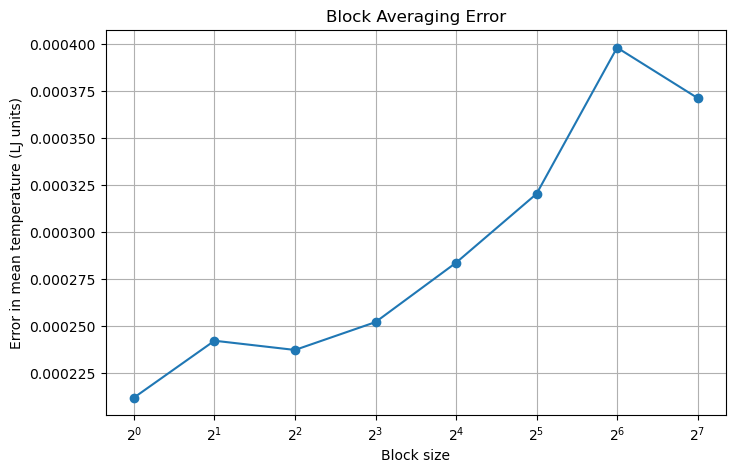

Mean temperature = 0.2500731977800202


In [82]:
step = data2[:,18]
T = data2[:,19]
T = T[step >= 1000]
block_sizes = [1, 2, 4, 8, 16, 32, 64, 128]
errors = []

for block_size in block_sizes:
    nblocks = len(T) // block_size
    trimmed = T[:nblocks * block_size]
    blocks = trimmed.reshape(nblocks, block_size)
    block_means = np.mean(blocks, axis=1)
    s_block = np.std(block_means, ddof=1)
    error = s_block / np.sqrt(nblocks)
    errors.append(error)
    print("Block size =", block_size, "Number of blocks =", nblocks, "Error =", error)

plt.figure(figsize=(8, 5))
plt.plot(block_sizes, errors, "o-")
plt.xlabel("Block size")
plt.ylabel("Error in mean temperature (LJ units)")
plt.title("Block Averaging Error")
plt.xscale("log", base=2)
plt.grid()
plt.savefig("d2.png")
plt.show()

mean_T = np.mean(T)
print("Mean temperature =", mean_T)

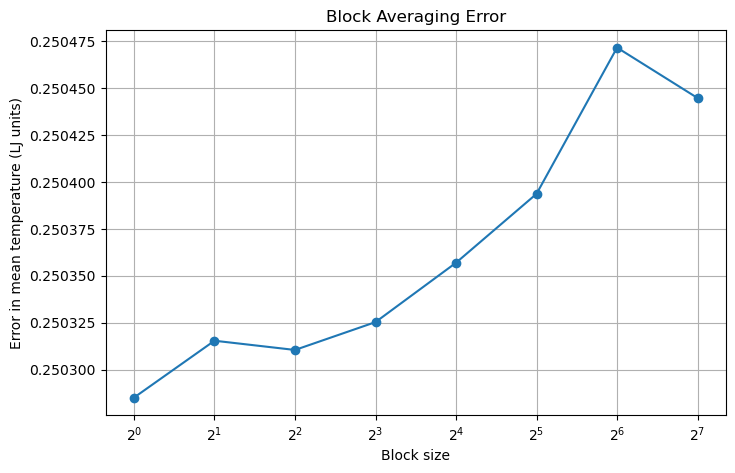

Mean temperature with error = [0.25028514 0.25031543 0.25031051 0.25032535 0.25035695 0.25039364
 0.25047147 0.25044464]


In [85]:
T_error = mean_T + errors
plt.figure(figsize=(8, 5))
plt.plot(block_sizes, T_error, "o-")
plt.xlabel("Block size")
plt.ylabel("Error in mean temperature (LJ units)")
plt.title("Block Averaging Error")
plt.xscale("log", base=2)
plt.grid()
plt.savefig("d22.png")
plt.show()

print("Mean temperature with error =", T_error)